# Step 2: EDA on the current EB-NeRD small training split

This notebook adapts the original top-level `EDA.ipynb` to the model-training files in `BT4222 Shared Final Folder/train_val/`. It reads train behaviors and fixed history plus the shared article catalogue. Run it in Colab to regenerate every table and plot. The numerical findings in the original notebook came from a different dataset and are not reused here.

EDA is descriptive. Candidate CTR is clicks among shown candidate articles; the final Step 3 feature files are built separately. The engineered-feature sample near the end examines only articles published in the preceding 24 hours, while Step 3 saves all candidate rows with an eligibility indicator.

In [29]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from google.colab import drive

In [30]:
drive.mount("/content/drive")

COLAB_ROOT = Path("/content/drive/MyDrive/Colab Notebooks")
TRAIN_VAL_ROOT = COLAB_ROOT / "BT4222 Shared Final Folder" / "train_val"
TRAIN_DIR = TRAIN_VAL_ROOT / "train"
BEHAVIOR_PATH = next(
    (path for path in (TRAIN_DIR / "behaviors.parquet", TRAIN_DIR / "behaviours.parquet")
     if path.is_file()),
    None,
)
HISTORY_PATH = TRAIN_DIR / "history.parquet"
ARTICLE_PATH = TRAIN_VAL_ROOT / "articles.parquet"
if BEHAVIOR_PATH is None:
    raise FileNotFoundError(f"Train behaviors missing from {TRAIN_DIR}")
for path in (HISTORY_PATH, ARTICLE_PATH):
    if not path.is_file():
        raise FileNotFoundError(path)

required_behavior = [
    "impression_id", "user_id", "impression_time", "article_id",
    "device_type", "is_sso_user", "is_subscriber",
    "article_ids_inview", "article_ids_clicked",
]
optional_behavior = ["age", "gender", "postcode"]
required_history = [
    "user_id", "article_id_fixed", "impression_time_fixed",
    "read_time_fixed", "scroll_percentage_fixed",
]
required_article = [
    "article_id", "category", "article_type", "topics", "premium", "published_time",
]
optional_article = ["subcategory"]

def available_columns(path, required, optional=()):
    names = set(pq.ParquetFile(path).schema_arrow.names)
    missing = set(required) - names
    if missing:
        raise ValueError(f"{path} is missing required EDA fields: {sorted(missing)}")
    return [*required, *(name for name in optional if name in names)]

df_behaviors_train = pd.read_parquet(
    BEHAVIOR_PATH,
    columns=available_columns(BEHAVIOR_PATH, required_behavior, optional_behavior),
)
df_history_train = pd.read_parquet(
    HISTORY_PATH, columns=available_columns(HISTORY_PATH, required_history),
)
df_articles = pd.read_parquet(
    ARTICLE_PATH,
    columns=available_columns(ARTICLE_PATH, required_article, optional_article),
)

duplicate_article_ids = int(df_articles["article_id"].duplicated().sum())
if duplicate_article_ids:
    print(f"Dropped {duplicate_article_ids:,} duplicate article IDs (first row kept)")
    df_articles = df_articles.drop_duplicates("article_id", keep="first").copy()

print("Train behaviors:", BEHAVIOR_PATH)
print("Train history:", HISTORY_PATH)
print("Articles:", ARTICLE_PATH)
print("Optional user fields available:", [name for name in optional_behavior if name in df_behaviors_train])
print("Rows:", {"behaviors": len(df_behaviors_train),
                "history_users": len(df_history_train), "articles": len(df_articles)})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train behaviors: /content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder/train_val/train/behaviors.parquet
Train history: /content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder/train_val/train/history.parquet
Articles: /content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder/train_val/articles.parquet
Optional user fields available: ['age', 'gender', 'postcode']
Rows: {'behaviors': 232887, 'history_users': 15143, 'articles': 20738}


The paths above match Step 3. This notebook uses the train split for exploratory feature decisions; validation and test are reserved for later model assessment. Only columns used below are read, avoiding the large article body text.


In [31]:
df_behaviors_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232887 entries, 0 to 232886
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   impression_id        232887 non-null  uint32        
 1   user_id              232887 non-null  uint32        
 2   impression_time      232887 non-null  datetime64[us]
 3   article_id           70421 non-null   float64       
 4   device_type          232887 non-null  int8          
 5   is_sso_user          232887 non-null  bool          
 6   is_subscriber        232887 non-null  bool          
 7   article_ids_inview   232887 non-null  object        
 8   article_ids_clicked  232887 non-null  object        
 9   age                  6341 non-null    float64       
 10  gender               16219 non-null   float64       
 11  postcode             4673 non-null    float64       
dtypes: bool(2), datetime64[us](1), float64(4), int8(1), object(2), uint32(2)

In [32]:
df_history_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15143 entries, 0 to 15142
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   user_id                  15143 non-null  uint32
 1   article_id_fixed         15143 non-null  object
 2   impression_time_fixed    15143 non-null  object
 3   read_time_fixed          15143 non-null  object
 4   scroll_percentage_fixed  15143 non-null  object
dtypes: object(4), uint32(1)
memory usage: 532.5+ KB


In [33]:
df_articles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20738 entries, 0 to 20737
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   article_id      20738 non-null  int32         
 1   category        20738 non-null  int16         
 2   article_type    20738 non-null  object        
 3   topics          20738 non-null  object        
 4   premium         20738 non-null  bool          
 5   published_time  20738 non-null  datetime64[us]
 6   subcategory     20738 non-null  object        
dtypes: bool(1), datetime64[us](1), int16(1), int32(1), object(3)
memory usage: 790.0+ KB


## User-related fields

Check coverage for `age`, `gender`, and `postcode` where present. The original EDA found high missingness in a different dataset; use the percentages computed below for this train split. `is_subscriber` is retained for descriptive CTR comparisons.

In [34]:
# Create working copy
beh = df_behaviors_train.copy()

# Number of candidate articles shown in each impression
beh["n_exposures"] = (
    beh["article_ids_inview"]
    .apply(len)
)

# Number of candidate articles clicked in each impression
beh["n_clicks"] = [
    len(set(inview) & set(clicked))
    for inview, clicked in zip(beh["article_ids_inview"], beh["article_ids_clicked"])
]

In [35]:
user_fields = [
    name for name in ("gender", "age", "is_subscriber", "postcode")
    if name in df_behaviors_train.columns
]
missing_user_fields = set(("gender", "age", "is_subscriber", "postcode")) - set(user_fields)
if missing_user_fields:
    print("Fields absent from this train file:", sorted(missing_user_fields))

user_df = df_behaviors_train[["user_id", *user_fields]].drop_duplicates("user_id")
for col in user_fields:
    print(f"\n===== {col} =====")
    print(f"Missing: {user_df[col].isna().mean() * 100:.2f}%")
    print("Unique non-null values:", user_df[col].nunique(dropna=True))
    print(user_df[col].value_counts(dropna=False, normalize=True).mul(100).head(20))


===== gender =====
Missing: 95.78%
Unique non-null values: 2
gender
NaN    95.780228
0.0     3.585815
1.0     0.633956
Name: proportion, dtype: float64

===== age =====
Missing: 98.34%
Unique non-null values: 9
age
NaN     98.335865
60.0     0.396223
50.0     0.389619
40.0     0.323582
70.0     0.264148
30.0     0.178300
20.0     0.059433
80.0     0.033019
90.0     0.013207
0.0      0.006604
Name: proportion, dtype: float64

===== is_subscriber =====
Missing: 0.00%
Unique non-null values: 2
is_subscriber
False    96.651918
True      3.348082
Name: proportion, dtype: float64

===== postcode =====
Missing: 98.78%
Unique non-null values: 5
postcode
NaN    98.778313
0.0     0.442449
1.0     0.224526
2.0     0.191508
3.0     0.184904
4.0     0.178300
Name: proportion, dtype: float64


In [36]:
binary_cols = [
    "is_subscriber",
]

# One row per user
user_binary = (
    df_behaviors_train[
        ["user_id"] + binary_cols
    ]
    .drop_duplicates("user_id")
)

for col in binary_cols:
    print(f"\n===== {col} =====")

    dist = (
        user_binary[col]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .mul(100)
    )

    print(dist)


===== is_subscriber =====
is_subscriber
False    96.651918
True      3.348082
Name: proportion, dtype: float64


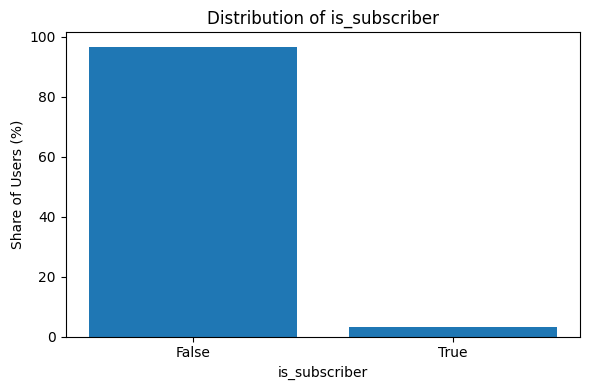

In [37]:
for col in binary_cols:
    dist = (
        user_binary[col]
        .value_counts(normalize=True)
        .mul(100)
        .reset_index()
    )

    dist.columns = [
        col,
        "user_share_pct"
    ]

    plt.figure(figsize=(6, 4))

    plt.bar(
        dist[col].astype(str),
        dist["user_share_pct"]
    )

    plt.xlabel(col)
    plt.ylabel("Share of Users (%)")
    plt.title(
        f"Distribution of {col}"
    )

    plt.tight_layout()
    plt.show()

In [38]:
for col in binary_cols:
    ctr_table = (
        beh.groupby(col)
        .agg(
            exposures=(
                "n_exposures",
                "sum"
            ),
            clicks=(
                "n_clicks",
                "sum"
            )
        )
        .reset_index()
    )

    ctr_table["candidate_ctr"] = (
        ctr_table["clicks"]
        / ctr_table["exposures"]
    )

    print(f"\n===== {col} CTR =====")
    print(ctr_table)


===== is_subscriber CTR =====
   is_subscriber  exposures  clicks  candidate_ctr
0          False    2407133  218280       0.090680
1           True     178614   15483       0.086684


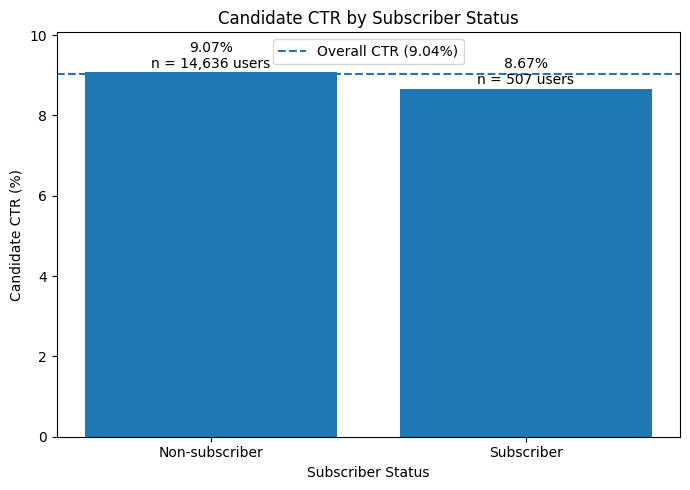

In [39]:
overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)

# CTR by subscriber status
subscriber_ctr = (
    beh.groupby("is_subscriber")
    .agg(
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
    .reset_index()
)

subscriber_ctr["candidate_ctr"] = (
    subscriber_ctr["clicks"]
    / subscriber_ctr["exposures"]
)

# Unique user count by subscriber status
subscriber_users = (
    beh.groupby("is_subscriber")["user_id"]
    .nunique()
    .reset_index(name="user_count")
)

# Merge CTR and user counts
plot_df = subscriber_ctr.merge(
    subscriber_users,
    on="is_subscriber"
)

plot_df["status"] = (
    plot_df["is_subscriber"]
    .map({
        False: "Non-subscriber",
        True: "Subscriber"
    })
)

plot_df["ctr_pct"] = (
    plot_df["candidate_ctr"]
    * 100
)

# Plot
plt.figure(figsize=(7, 5))

bars = plt.bar(
    plot_df["status"],
    plot_df["ctr_pct"]
)

# Overall CTR reference line
plt.axhline(
    overall_ctr * 100,
    linestyle="--",
    label=f"Overall CTR ({overall_ctr * 100:.2f}%)"
)

# Add CTR + user count labels
for bar, (_, row) in zip(
    bars,
    plot_df.iterrows()
):
    height = bar.get_height()

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.03,
        (
            f"{row['ctr_pct']:.2f}%\n"
            f"n = {row['user_count']:,} users"
        ),
        ha="center",
        va="bottom"
    )

plt.xlabel("Subscriber Status")
plt.ylabel("Candidate CTR (%)")
plt.title(
    "Candidate CTR by Subscriber Status"
)

plt.legend()

# Give space for labels above bars
plt.ylim(
    0,
    plot_df["ctr_pct"].max() + 1
)

plt.tight_layout()
plt.show()

### Notes to update after running on the current train split

- Use the missingness and user counts above to decide whether `age`, `gender`, and `postcode` have enough coverage for analysis.
- Compare subscriber exposure share with candidate CTR. A small raw CTR difference is descriptive and may still matter through interaction with article `premium` status.
- Do not reuse the percentages reported in the original large-dataset notebook.

## Impression and context fields

Inspect `device_type`, `is_sso_user`, front-page context, hour, and weekday. These are available at impression time. Candidate CTR is shown alongside exposure counts so small groups are visible.

In [40]:
# Create working copy
beh = df_behaviors_train.copy()

# Helper columns for candidate-level CTR
beh["n_exposures"] = (
    beh["article_ids_inview"]
    .apply(len)
)

beh["n_clicks"] = [
    len(set(inview) & set(clicked))
    for inview, clicked in zip(beh["article_ids_inview"], beh["article_ids_clicked"])
]

# Derived context features
beh["is_front_page"] = (
    beh["article_id"]
    .isna()
)

beh["hour"] = (
    beh["impression_time"]
    .dt.hour
)

beh["day_of_week"] = (
    beh["impression_time"]
    .dt.dayofweek
)

weekday_map = {
    0: "Mon",
    1: "Tue",
    2: "Wed",
    3: "Thu",
    4: "Fri",
    5: "Sat",
    6: "Sun"
}

beh["weekday"] = (
    beh["day_of_week"]
    .map(weekday_map)
)


# =========================
# Distribution checks
# =========================

print("===== device_type =====")
print(
    beh["device_type"]
    .value_counts(
        dropna=False,
        normalize=True
    )
    .mul(100)
)

print(
    f"Missing: "
    f"{beh['device_type'].isna().mean() * 100:.2f}%"
)


print("\n===== is_sso_user =====")
print(
    beh["is_sso_user"]
    .value_counts(
        dropna=False,
        normalize=True
    )
    .mul(100)
)

print(
    f"Missing: "
    f"{beh['is_sso_user'].isna().mean() * 100:.2f}%"
)


print("\n===== page context =====")

page_dist = (
    beh["is_front_page"]
    .map({
        True: "Front page",
        False: "Article page"
    })
    .value_counts(
        normalize=True
    )
    .mul(100)
)

print(page_dist)


print("\n===== hour of day =====")
print(
    beh["hour"]
    .value_counts(
        normalize=True
    )
    .sort_index()
    .mul(100)
)


print("\n===== day of week =====")
print(
    beh["weekday"]
    .value_counts(
        normalize=True
    )
    .reindex([
        "Mon",
        "Tue",
        "Wed",
        "Thu",
        "Fri",
        "Sat",
        "Sun"
    ])
    .mul(100)
)

===== device_type =====
device_type
2    63.117735
1    34.165067
3     2.717198
Name: proportion, dtype: float64
Missing: 0.00%

===== is_sso_user =====
is_sso_user
False    89.86633
True     10.13367
Name: proportion, dtype: float64
Missing: 0.00%

===== page context =====
is_front_page
Front page      69.76173
Article page    30.23827
Name: proportion, dtype: float64

===== hour of day =====
hour
0     0.543182
1     0.659118
2     0.965704
3     2.744679
4     5.165166
5     6.499289
6     6.969045
7     6.291034
8     4.788588
9     4.319692
10    4.591068
11    4.296075
12    4.495743
13    4.772701
14    4.823799
15    4.966357
16    4.711298
17    5.414214
18    5.676573
19    5.644368
20    5.345082
21    3.661432
22    1.775539
23    0.880255
Name: proportion, dtype: float64

===== day of week =====
weekday
Mon    15.033042
Tue    13.868529
Wed    13.837183
Thu    15.212099
Fri    15.800367
Sat    12.730638
Sun    13.518144
Name: proportion, dtype: float64


In [41]:
# Overall CTR
overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)

# Features to compare against CTR
context_features = [
    "device_type",
    "is_sso_user",
    "is_front_page",
    "hour",
    "weekday"
]

ctr_results = {}

for col in context_features:
    ctr_table = (
        beh.groupby(
            col,
            observed=True
        )
        .agg(
            impressions=(
                "impression_id",
                "size"
            ),
            exposures=(
                "n_exposures",
                "sum"
            ),
            clicks=(
                "n_clicks",
                "sum"
            )
        )
        .reset_index()
    )

    ctr_table["candidate_ctr"] = (
        ctr_table["clicks"]
        / ctr_table["exposures"]
    )

    ctr_results[col] = ctr_table

    print(f"\n===== {col} CTR =====")
    print(ctr_table)

print(
    f"\nOverall CTR: "
    f"{overall_ctr * 100:.2f}%"
)


===== device_type CTR =====
   device_type  impressions  exposures  clicks  candidate_ctr
0            1        79566     940311   80029       0.085109
1            2       146993    1563286  147402       0.094290
2            3         6328      82150    6332       0.077079

===== is_sso_user CTR =====
   is_sso_user  impressions  exposures  clicks  candidate_ctr
0        False       209287    2315626  209982       0.090680
1         True        23600     270121   23781       0.088038

===== is_front_page CTR =====
   is_front_page  impressions  exposures  clicks  candidate_ctr
0          False        70421     815901   70477       0.086379
1           True       162466    1769846  163286       0.092260

===== hour CTR =====
    hour  impressions  exposures  clicks  candidate_ctr
0      0         1265      15092    1280       0.084813
1      1         1535      17964    1539       0.085671
2      2         2249      24712    2253       0.091170
3      3         6392      70813    640

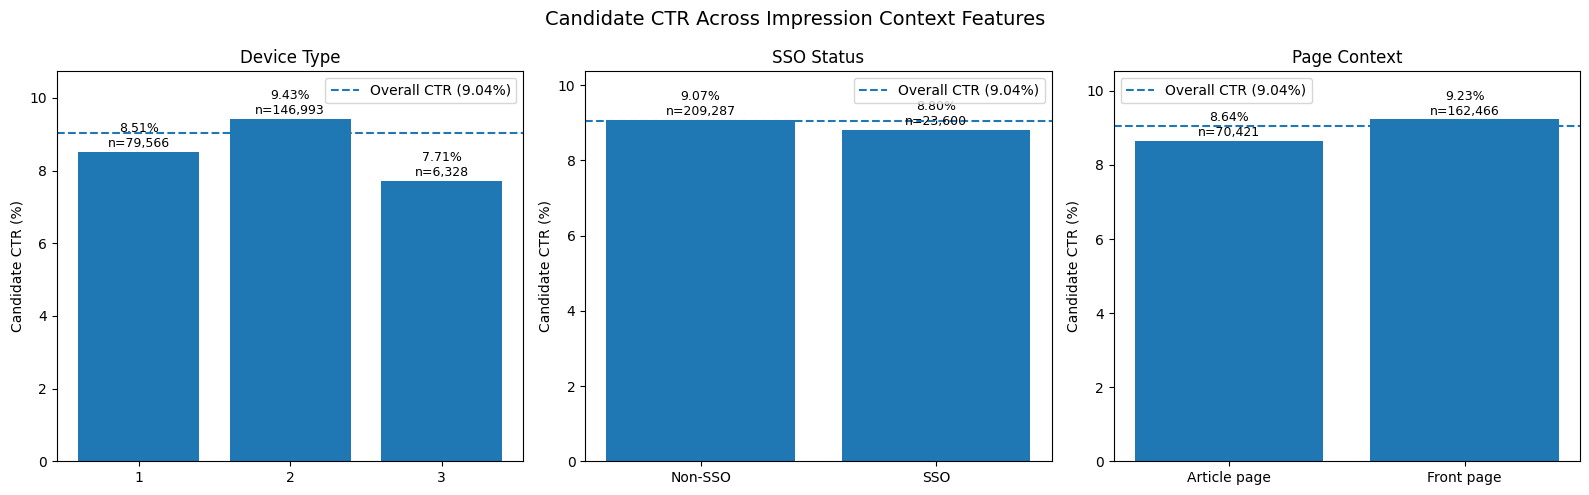

In [42]:
# Overall candidate CTR
overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)

# Build CTR tables
features = [
    "device_type",
    "is_sso_user",
    "is_front_page"
]

ctr_results = {}

for col in features:
    table = (
        beh.groupby(col)
        .agg(
            impressions=(
                "impression_id",
                "size"
            ),
            exposures=(
                "n_exposures",
                "sum"
            ),
            clicks=(
                "n_clicks",
                "sum"
            )
        )
        .reset_index()
    )

    table["candidate_ctr"] = (
        table["clicks"]
        / table["exposures"]
    )

    ctr_results[col] = table


# -------------------------
# Plot all 3 together
# -------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

plot_info = [
    (
        "device_type",
        "Device Type",
        None
    ),
    (
        "is_sso_user",
        "SSO Status",
        {
            False: "Non-SSO",
            True: "SSO"
        }
    ),
    (
        "is_front_page",
        "Page Context",
        {
            False: "Article page",
            True: "Front page"
        }
    )
]

for ax, (col, title, label_map) in zip(
    axes,
    plot_info
):
    df = ctr_results[col].copy()

    # Create readable x labels
    if label_map is not None:
        df["label"] = (
            df[col]
            .map(label_map)
        )
    else:
        df["label"] = (
            df[col]
            .astype(str)
        )

    # CTR in percentage points
    df["ctr_pct"] = (
        df["candidate_ctr"]
        * 100
    )

    bars = ax.bar(
        df["label"],
        df["ctr_pct"]
    )

    # Overall CTR reference
    ax.axhline(
        overall_ctr * 100,
        linestyle="--",
        label=(
            f"Overall CTR "
            f"({overall_ctr * 100:.2f}%)"
        )
    )

    # Annotate each bar
    for bar, (_, row) in zip(
        bars,
        df.iterrows()
    ):
        height = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            height + 0.05,
            (
                f"{row['ctr_pct']:.2f}%\n"
                f"n={row['impressions']:,}"
            ),
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(
        "Candidate CTR (%)"
    )

    ax.legend()

    # Give enough room for labels
    ax.set_ylim(
        0,
        df["ctr_pct"].max() + 1.3
    )

plt.suptitle(
    "Candidate CTR Across Impression Context Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

===== CTR by Hour =====
    hour  impressions  exposures  clicks  candidate_ctr
0      0         1265      15092    1280       0.084813
1      1         1535      17964    1539       0.085671
2      2         2249      24712    2253       0.091170
3      3         6392      70813    6402       0.090407
4      4        12029     132851   12071       0.090861
5      5        15136     171044   15171       0.088696
6      6        16230     184955   16291       0.088081
7      7        14651     166240   14719       0.088541
8      8        11152     123773   11186       0.090375
9      9        10060     113058   10100       0.089335
10    10        10692     117185   10753       0.091761
11    11        10005     109486   10083       0.092094
12    12        10470     111343   10509       0.094384
13    13        11115     118797   11156       0.093908
14    14        11234     124157   11285       0.090893
15    15        11566     125656   11607       0.092371
16    16        10972   

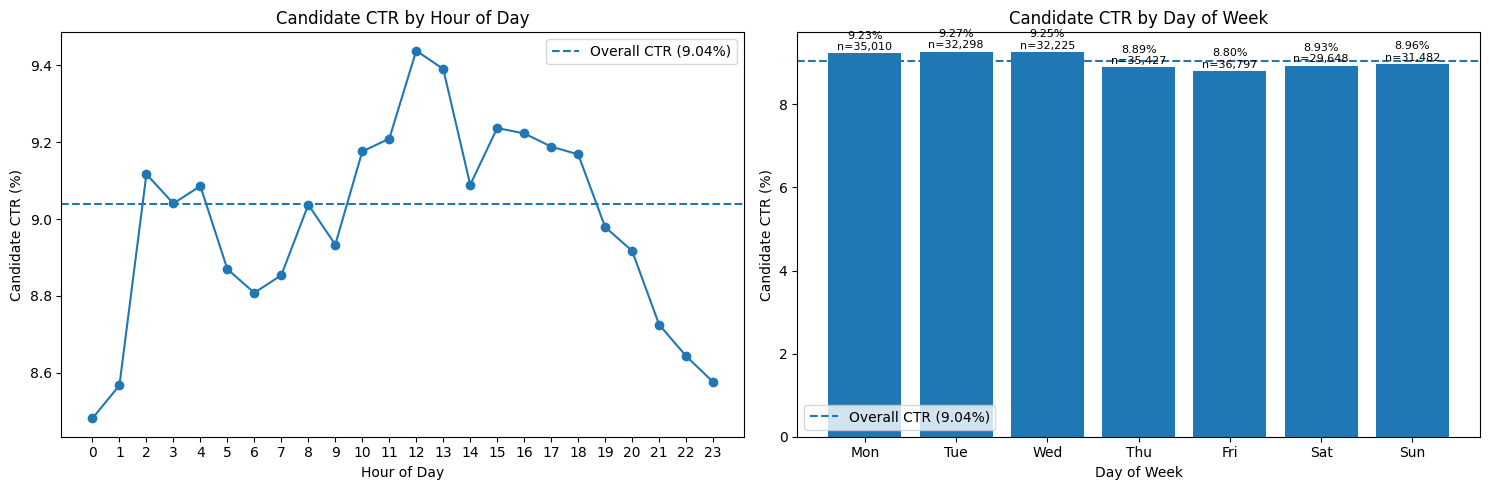

In [43]:
# -------------------------
# Derive time features
# -------------------------

beh["hour"] = (
    beh["impression_time"]
    .dt.hour
)

beh["day_of_week"] = (
    beh["impression_time"]
    .dt.dayofweek
)

weekday_map = {
    0: "Mon",
    1: "Tue",
    2: "Wed",
    3: "Thu",
    4: "Fri",
    5: "Sat",
    6: "Sun"
}

beh["weekday"] = (
    beh["day_of_week"]
    .map(weekday_map)
)


# -------------------------
# Overall CTR
# -------------------------

overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)


# -------------------------
# CTR by hour
# -------------------------

hour_ctr = (
    beh.groupby("hour")
    .agg(
        impressions=(
            "impression_id",
            "size"
        ),
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
    .reset_index()
)

hour_ctr["candidate_ctr"] = (
    hour_ctr["clicks"]
    / hour_ctr["exposures"]
)


# -------------------------
# CTR by weekday
# -------------------------

weekday_order = [
    "Mon",
    "Tue",
    "Wed",
    "Thu",
    "Fri",
    "Sat",
    "Sun"
]

weekday_ctr = (
    beh.groupby(
        "weekday",
        observed=True
    )
    .agg(
        impressions=(
            "impression_id",
            "size"
        ),
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
    .reset_index()
)

weekday_ctr["candidate_ctr"] = (
    weekday_ctr["clicks"]
    / weekday_ctr["exposures"]
)

weekday_ctr["weekday"] = pd.Categorical(
    weekday_ctr["weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_ctr = (
    weekday_ctr
    .sort_values("weekday")
)


# -------------------------
# Print descriptive tables
# -------------------------

print("===== CTR by Hour =====")
print(hour_ctr)

print("\n===== CTR by Weekday =====")
print(weekday_ctr)


# -------------------------
# Plot
# -------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# Hour-of-day CTR
axes[0].plot(
    hour_ctr["hour"],
    hour_ctr["candidate_ctr"] * 100,
    marker="o"
)

axes[0].axhline(
    overall_ctr * 100,
    linestyle="--",
    label=(
        f"Overall CTR "
        f"({overall_ctr * 100:.2f}%)"
    )
)

axes[0].set_xlabel(
    "Hour of Day"
)

axes[0].set_ylabel(
    "Candidate CTR (%)"
)

axes[0].set_title(
    "Candidate CTR by Hour of Day"
)

axes[0].set_xticks(
    range(24)
)

axes[0].legend()


# Weekday CTR
bars = axes[1].bar(
    weekday_ctr["weekday"].astype(str),
    weekday_ctr["candidate_ctr"] * 100
)

axes[1].axhline(
    overall_ctr * 100,
    linestyle="--",
    label=(
        f"Overall CTR "
        f"({overall_ctr * 100:.2f}%)"
    )
)

# Add CTR and impression count
for bar, (_, row) in zip(
    bars,
    weekday_ctr.iterrows()
):
    height = bar.get_height()

    axes[1].text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.03,
        (
            f"{row['candidate_ctr'] * 100:.2f}%\n"
            f"n={row['impressions']:,}"
        ),
        ha="center",
        va="bottom",
        fontsize=8
    )

axes[1].set_xlabel(
    "Day of Week"
)

axes[1].set_ylabel(
    "Candidate CTR (%)"
)

axes[1].set_title(
    "Candidate CTR by Day of Week"
)

axes[1].legend()

plt.tight_layout()
plt.show()

### Notes to update after running on the current train split

- Compare device, SSO, and page-context CTR with their exposure counts; low-count groups can be unstable.
- Hour and weekday may describe audience behavior but are shared by candidates within an impression, so assess them alongside candidate-specific features when ranking.

## Fixed-history fields

Measure history length, median valid read time, and mean valid scroll percentage per user. The fixed-history events precede the train behavior period; compare their distributions and user-level CTR groups.

In [44]:
history = df_history_train.copy()

def safe_numeric_array(values, upper=None):
    if values is None:
        return np.array([], dtype=float)
    arr = np.asarray(values, dtype=float)
    valid = np.isfinite(arr) & (arr >= 0)
    if upper is not None:
        valid &= arr <= upper
    return arr[valid]

def median_or_nan(values):
    valid = safe_numeric_array(values)
    return float(np.median(valid)) if valid.size else np.nan

def mean_scroll_or_nan(values):
    valid = safe_numeric_array(values, upper=100)
    return float(np.mean(valid)) if valid.size else np.nan

history["history_length"] = history["article_id_fixed"].map(len)
history["median_read_time"] = history["read_time_fixed"].map(median_or_nan)
history["mean_scroll_percentage"] = history["scroll_percentage_fixed"].map(mean_scroll_or_nan)

for col in ("history_length", "median_read_time", "mean_scroll_percentage"):
    print(f"\n===== {col} =====")
    print(history[col].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))
    print(f"Missing: {history[col].isna().mean() * 100:.2f}%")


===== history_length =====
count    15143.000000
mean       160.222347
std        178.785697
min          5.000000
25%         35.000000
50%         93.000000
75%        222.000000
90%        414.000000
95%        545.000000
99%        802.580000
max       1896.000000
Name: history_length, dtype: float64
Missing: 0.00%

===== median_read_time =====
count    15143.000000
mean        23.804431
std         22.066354
min          0.000000
25%         10.000000
50%         17.000000
75%         30.000000
90%         49.000000
95%         63.500000
99%        104.500000
max        398.000000
Name: median_read_time, dtype: float64
Missing: 0.00%

===== mean_scroll_percentage =====
count    15141.000000
mean        70.382788
std         13.393977
min         12.200000
25%         60.869919
50%         70.333333
75%         80.111111
90%         88.301887
95%         92.454936
99%         98.696753
max        100.000000
Name: mean_scroll_percentage, dtype: float64
Missing: 0.01%


In [45]:
import pandas as pd
import numpy as np

# =========================================
# 1. Aggregate behaviour to user level FIRST
# =========================================

user_beh = (
    beh.groupby(
        "user_id",
        as_index=False,
        sort=False
    )
    .agg(
        impressions=(
            "impression_id",
            "size"
        ),
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
)

print("Users with train impressions:", len(user_beh))


# =========================================
# 2. Create groups on history table
# =========================================

history["history_length_group"] = pd.cut(
    history["history_length"],
    bins=[
        0,
        10,
        50,
        100,
        300,
        np.inf
    ],
    labels=[
        "0-9",
        "10-49",
        "50-99",
        "100-299",
        "300+"
    ],
    right=False
)

def quartile_labels(series):
    labels = pd.Series(pd.NA, index=series.index, dtype="object")
    valid = series.dropna()
    if valid.empty:
        return labels
    if valid.nunique() < 2:
        labels.loc[valid.index] = "Q1"
        return labels
    codes = pd.qcut(valid, q=4, labels=False, duplicates="drop")
    labels.loc[codes.index] = codes.map(lambda code: f"Q{int(code) + 1}")
    return labels

history["read_time_group"] = quartile_labels(history["median_read_time"])
history["scroll_group"] = quartile_labels(history["mean_scroll_percentage"])


# =========================================
# 3. Merge at USER level
# =========================================

user_analysis = user_beh.merge(
    history[
        [
            "user_id",
            "history_length_group",
            "read_time_group",
            "scroll_group"
        ]
    ],
    on="user_id",
    how="left"
)


# =========================================
# 4. Calculate CTR
# =========================================

def ctr_by_group(df, column):
    result = (
        df.groupby(
            column,
            observed=True
        )
        .agg(
            users=(
                "user_id",
                "size"
            ),
            impressions=(
                "impressions",
                "sum"
            ),
            exposures=(
                "exposures",
                "sum"
            ),
            clicks=(
                "clicks",
                "sum"
            )
        )
        .reset_index()
    )

    result["candidate_ctr"] = (
        result["clicks"]
        / result["exposures"]
    )

    return result


history_ctr = ctr_by_group(
    user_analysis,
    "history_length_group"
)

read_ctr = ctr_by_group(
    user_analysis,
    "read_time_group"
)

scroll_ctr = ctr_by_group(
    user_analysis,
    "scroll_group"
)


print("===== History Length CTR =====")
print(history_ctr)

print("\n===== Read Time CTR =====")
print(read_ctr)

print("\n===== Scroll Percentage CTR =====")
print(scroll_ctr)

Users with train impressions: 15143
===== History Length CTR =====
  history_length_group  users  impressions  exposures  clicks  candidate_ctr
0                  0-9    819         3809      44542    3814       0.085627
1                10-49   4182        22605     273148   22701       0.083109
2                50-99   2888        26051     309052   26148       0.084607
3              100-299   4695        80426     908940   80790       0.088884
4                 300+   2559        99996    1050065  100310       0.095527

===== Read Time CTR =====
  read_time_group  users  impressions  exposures  clicks  candidate_ctr
0              Q1   4130        61444     611480   61613       0.100760
1              Q2   3612        61286     657462   61424       0.093426
2              Q3   3660        60220     686533   60399       0.087977
3              Q4   3741        49937     630272   50327       0.079850

===== Scroll Percentage CTR =====
  scroll_group  users  impressions  exposures  cl

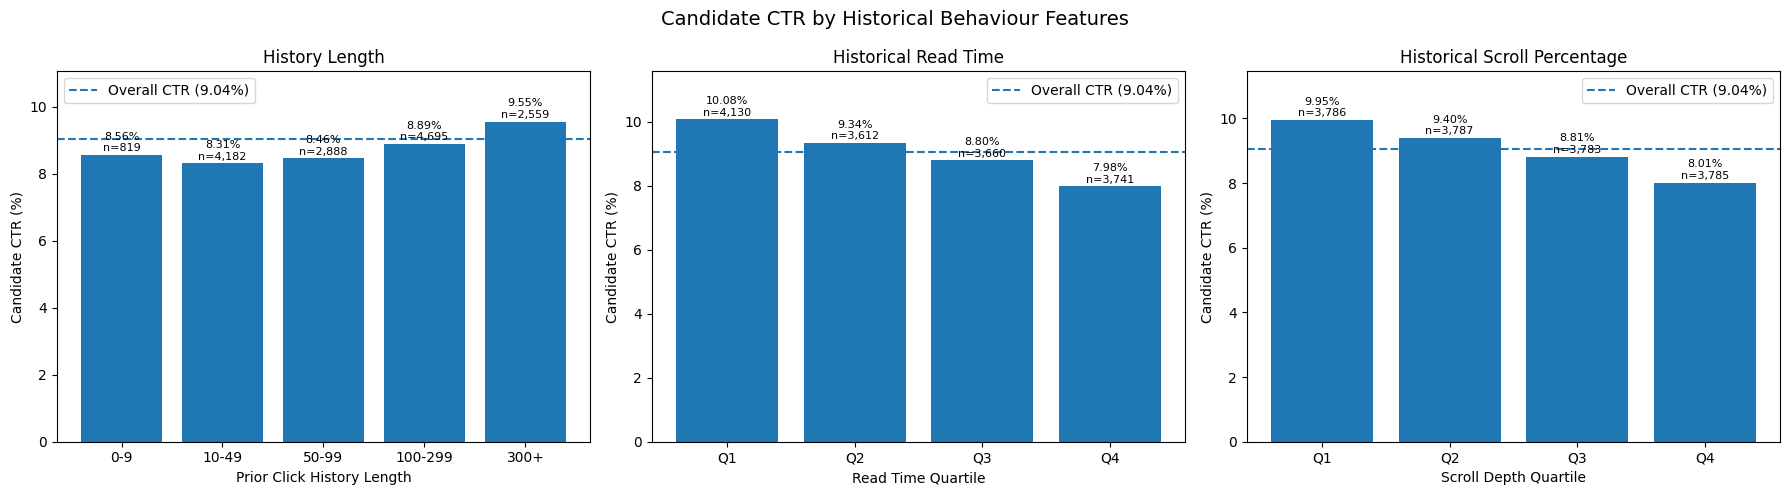

In [46]:
import matplotlib.pyplot as plt

overall_ctr = (
    user_analysis["clicks"].sum()
    / user_analysis["exposures"].sum()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

plot_info = [
    (
        history_ctr,
        "history_length_group",
        "History Length",
        "Prior Click History Length"
    ),
    (
        read_ctr,
        "read_time_group",
        "Historical Read Time",
        "Read Time Quartile"
    ),
    (
        scroll_ctr,
        "scroll_group",
        "Historical Scroll Percentage",
        "Scroll Depth Quartile"
    )
]

for ax, (
    df,
    group_col,
    title,
    xlabel
) in zip(
    axes,
    plot_info
):
    bars = ax.bar(
        df[group_col].astype(str),
        df["candidate_ctr"] * 100
    )

    # Overall CTR reference line
    ax.axhline(
        overall_ctr * 100,
        linestyle="--",
        label=(
            f"Overall CTR "
            f"({overall_ctr * 100:.2f}%)"
        )
    )

    # Add CTR + number of users
    for bar, (_, row) in zip(
        bars,
        df.iterrows()
    ):
        height = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            height + 0.05,
            (
                f"{row['candidate_ctr'] * 100:.2f}%\n"
                f"n={row['users']:,}"
            ),
            ha="center",
            va="bottom",
            fontsize=8
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Candidate CTR (%)")
    ax.legend()

    ax.set_ylim(
        0,
        df["candidate_ctr"].max() * 100 + 1.5
    )

plt.suptitle(
    "Candidate CTR by Historical Behaviour Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Notes to update after running on the current train split

- Check whether CTR changes across history-length groups and read/scroll quartiles, and report each group's user and exposure counts.
- These are associations, not evidence that reading longer causes more or fewer clicks. A user's profile is shared by all candidates in one impression.

## Article fields

Inspect `category`, `article_type`, `premium`, and available multi-value tags (`subcategory` and `topics`). Catalogue distributions count articles; the CTR comparisons below count shown candidates, so the two distributions answer different questions.

In [47]:
for col in ("category", "subcategory", "article_type", "topics", "premium"):
    if col not in df_articles:
        print(f"{col}: not available in this catalogue")
        continue
    non_null = df_articles[col].dropna()
    print(col, type(non_null.iloc[0]) if not non_null.empty else "all values missing")

category <class 'numpy.int16'>
subcategory <class 'numpy.ndarray'>
article_type <class 'str'>
topics <class 'numpy.ndarray'>
premium <class 'numpy.bool'>


In [48]:
import numpy as np
import pandas as pd

# =========================================
# 1. Scalar article features
# =========================================

scalar_cols = [
    "category",
    "article_type",
    "premium"
]

for col in scalar_cols:
    if col not in df_articles:
        continue
    print(f"\n===== {col} =====")

    print(
        f"Missing: "
        f"{df_articles[col].isna().mean() * 100:.2f}%"
    )

    print(
        "Unique values:",
        df_articles[col].nunique()
    )

    print("\nDistribution:")
    print(
        df_articles[col]
        .value_counts(
            dropna=False,
            normalize=True
        )
        .mul(100)
        .head(20)
    )


# =========================================
# 2. Multi-value article features
# =========================================

multi_cols = [
    "subcategory",
    "topics"
]

for col in multi_cols:
    if col not in df_articles:
        continue
    print(f"\n===== {col} =====")

    # Number of values assigned to each article
    value_count = (
        df_articles[col]
        .apply(
            lambda x:
            len(x)
            if isinstance(x, (list, tuple, np.ndarray))
            else 0
        )
    )

    print(
        "Mean values per article:",
        round(value_count.mean(), 2)
    )

    print(
        "Median values per article:",
        value_count.median()
    )

    print(
        "Articles with no values:",
        f"{(value_count == 0).mean() * 100:.2f}%"
    )

    # Explode arrays into individual values
    exploded = (
        df_articles[col]
        .explode()
        .dropna()
    )

    print(
        "Unique values:",
        exploded.nunique()
    )

    print("\nMost common values:")
    print(
        exploded
        .value_counts()
        .head(20)
    )


===== category =====
Missing: 0.00%
Unique values: 25

Distribution:
category
118     20.961520
142     16.872408
414     16.790433
140     14.422799
572      7.758704
2889     7.069148
457      4.580962
565      3.698524
512      2.382100
498      1.866139
539      0.761886
68       0.650979
529      0.597936
2975     0.583470
2077     0.323078
561      0.188061
2        0.135018
1505     0.120552
2341     0.081975
22       0.053043
Name: proportion, dtype: float64

===== article_type =====
Missing: 0.00%
Unique values: 12

Distribution:
article_type
article_default                  87.395120
article_page_nine_girl            5.892564
article_video_standalone          3.852831
article_standard_feature          1.099431
article_scribblelive              0.752242
article_fullscreen_gallery        0.337545
article_opinionen                 0.323078
article_native                    0.216993
article_questions_and_answers     0.062687
article_webtv                     0.053043
article_fea

In [49]:
import pandas as pd
import gc

# Smaller = safer for RAM
chunk_size = 20_000

category_parts = []
article_type_parts = []
premium_parts = []


for start in range(
    0,
    len(df_behaviors_train),
    chunk_size
):
    end = min(
        start + chunk_size,
        len(df_behaviors_train)
    )

    # Only keep columns we actually need
    chunk = (
        df_behaviors_train
        .iloc[start:end][
            [
                "article_ids_inview",
                "article_ids_clicked"
            ]
        ]
        .copy()
    )

    # Convert clicked list to set
    # for faster membership checking
    chunk["clicked_set"] = (
        chunk["article_ids_clicked"]
        .apply(set)
    )

    # One row per candidate article
    chunk = (
        chunk
        .explode("article_ids_inview")
        .rename(
            columns={
                "article_ids_inview":
                "article_id"
            }
        )
    )

    # Empty slates are not candidate exposures.
    chunk = chunk.loc[chunk["article_id"].notna()].copy()

    # Candidate click label
    chunk["clicked"] = [
        int(article_id in clicked_set)
        for article_id, clicked_set
        in zip(
            chunk["article_id"],
            chunk["clicked_set"]
        )
    ]

    # Remove large columns ASAP
    chunk = chunk.drop(
        columns=[
            "article_ids_clicked",
            "clicked_set"
        ]
    )

    # Add article features
    chunk = chunk.merge(
        df_articles[
            [
                "article_id",
                "category",
                "article_type",
                "premium"
            ]
        ],
        on="article_id",
        how="left"
    )

    # -------------------------
    # Category
    # -------------------------
    category_chunk = (
        chunk.groupby(
            "category",
            dropna=False
        )
        .agg(
            exposures=(
                "clicked",
                "size"
            ),
            clicks=(
                "clicked",
                "sum"
            )
        )
        .reset_index()
    )

    category_parts.append(
        category_chunk
    )

    # -------------------------
    # Article type
    # -------------------------
    article_type_chunk = (
        chunk.groupby(
            "article_type",
            dropna=False
        )
        .agg(
            exposures=(
                "clicked",
                "size"
            ),
            clicks=(
                "clicked",
                "sum"
            )
        )
        .reset_index()
    )

    article_type_parts.append(
        article_type_chunk
    )

    # -------------------------
    # Premium
    # -------------------------
    premium_chunk = (
        chunk.groupby(
            "premium",
            dropna=False
        )
        .agg(
            exposures=(
                "clicked",
                "size"
            ),
            clicks=(
                "clicked",
                "sum"
            )
        )
        .reset_index()
    )

    premium_parts.append(
        premium_chunk
    )

    # Clear current chunk from memory
    del chunk
    gc.collect()

    print(
        f"Processed "
        f"{end:,} / "
        f"{len(df_behaviors_train):,}"
    )


# =========================================
# Combine chunk results
# =========================================

def combine_results(
    parts,
    feature
):
    result = (
        pd.concat(
            parts,
            ignore_index=True
        )
        .groupby(
            feature,
            dropna=False,
            as_index=False
        )[
            [
                "exposures",
                "clicks"
            ]
        ]
        .sum()
    )

    result["candidate_ctr"] = (
        result["clicks"]
        / result["exposures"]
    )

    result["exposure_share_pct"] = (
        result["exposures"]
        / result["exposures"].sum()
        * 100
    )

    return result.sort_values(
        "exposures",
        ascending=False
    )


category_ctr = combine_results(
    category_parts,
    "category"
)

article_type_ctr = combine_results(
    article_type_parts,
    "article_type"
)

premium_ctr = combine_results(
    premium_parts,
    "premium"
)


# =========================================
# Results
# =========================================

print("\n===== CATEGORY CTR =====")
print(category_ctr)

print("\n===== ARTICLE TYPE CTR =====")
print(article_type_ctr)

print("\n===== PREMIUM CTR =====")
print(premium_ctr)

Processed 20,000 / 232,887
Processed 40,000 / 232,887
Processed 60,000 / 232,887
Processed 80,000 / 232,887
Processed 100,000 / 232,887
Processed 120,000 / 232,887
Processed 140,000 / 232,887
Processed 160,000 / 232,887
Processed 180,000 / 232,887
Processed 200,000 / 232,887
Processed 220,000 / 232,887
Processed 232,887 / 232,887

===== CATEGORY CTR =====
    category  exposures  clicks  candidate_ctr  exposure_share_pct
1        118     790080   71797       0.090873           30.555194
3        142     562683   58118       0.103287           21.760946
4        414     465713   44397       0.095331           18.010772
2        140     363080   29376       0.080908           14.041590
5        457     113023    4696       0.041549            4.371000
15      2975      88060    8771       0.099603            3.405592
7        512      61697    8616       0.139650            2.386042
6        498      51952    6140       0.118186            2.009168
11       565      47656    1401       0

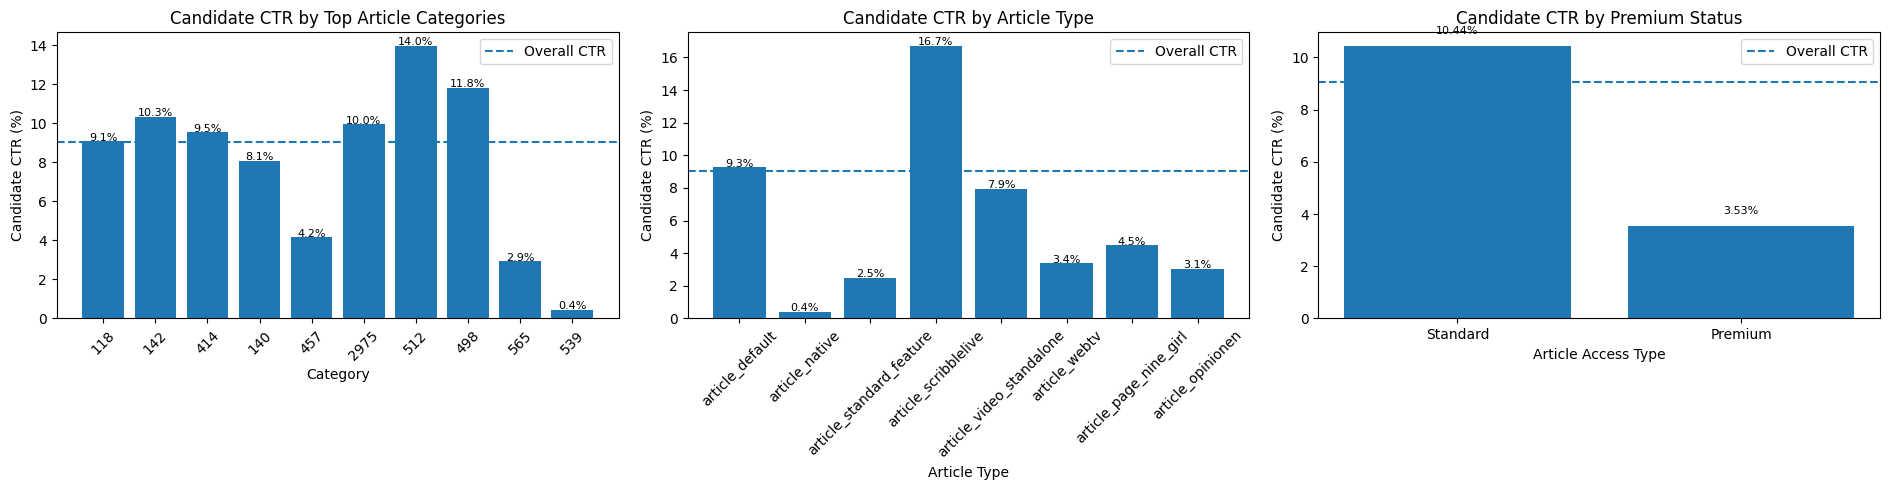

In [50]:
import matplotlib.pyplot as plt

overall_ctr = beh["n_clicks"].sum() / beh["n_exposures"].sum()

# Keep only the most exposed categories for readability
top_categories = (
    category_ctr
    .head(10)
    .copy()
)

# Keep article types with meaningful exposure
top_article_types = (
    article_type_ctr
    .head(8)
    .copy()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5)
)

# =========================
# Category
# =========================
bars = axes[0].bar(
    top_categories["category"].astype(str),
    top_categories["candidate_ctr"] * 100
)

axes[0].axhline(
    overall_ctr * 100,
    linestyle="--",
    label="Overall CTR"
)

axes[0].set_title(
    "Candidate CTR by Top Article Categories"
)

axes[0].set_xlabel("Category")
axes[0].set_ylabel("Candidate CTR (%)")
axes[0].tick_params(
    axis="x",
    rotation=45
)

for bar, (_, row) in zip(
    bars,
    top_categories.iterrows()
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{row['candidate_ctr'] * 100:.1f}%",
        ha="center",
        fontsize=8
    )

axes[0].legend()


# =========================
# Article type
# =========================
bars = axes[1].bar(
    top_article_types["article_type"],
    top_article_types["candidate_ctr"] * 100
)

axes[1].axhline(
    overall_ctr * 100,
    linestyle="--",
    label="Overall CTR"
)

axes[1].set_title(
    "Candidate CTR by Article Type"
)

axes[1].set_xlabel("Article Type")
axes[1].set_ylabel("Candidate CTR (%)")

axes[1].tick_params(
    axis="x",
    rotation=45
)

for bar, (_, row) in zip(
    bars,
    top_article_types.iterrows()
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{row['candidate_ctr'] * 100:.1f}%",
        ha="center",
        fontsize=8
    )

axes[1].legend()


# =========================
# Premium
# =========================
premium_plot = premium_ctr.copy()

premium_plot["label"] = (
    premium_plot["premium"]
    .map({
        False: "Standard",
        True: "Premium"
    })
)

bars = axes[2].bar(
    premium_plot["label"],
    premium_plot["candidate_ctr"] * 100
)

axes[2].axhline(
    overall_ctr * 100,
    linestyle="--",
    label="Overall CTR"
)

axes[2].set_title(
    "Candidate CTR by Premium Status"
)

axes[2].set_xlabel("Article Access Type")
axes[2].set_ylabel("Candidate CTR (%)")

for bar, (_, row) in zip(
    bars,
    premium_plot.iterrows()
):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        (
            f"{row['candidate_ctr'] * 100:.2f}%\n"
        ),
        ha="center",
        fontsize=8
    )

axes[2].legend()

plt.tight_layout()
plt.show()

## Current-train EDA notes for feature selection

| Field group | What to check after running | Model handling |
| --- | --- | --- |
| `age`, `gender`, `postcode` | Confirm availability and missingness in this train split. | Include only if coverage and evaluation justify it. |
| `device_type`, `category`, `article_type` | Compare exposure counts and candidate CTR. | Treat codes as categories, not ordered quantities. Step 3 one-hot encodes these. |
| `is_subscriber`, `is_sso_user`, `premium`, `is_front_page` | Compare group sizes and CTR. | Keep as binary features; subscriber and premium can interact. |
| `read_time`, `scroll_percentage`, `next_read_time`, `next_scroll_percentage` | These concern the current recommendation outcome. | Exclude from predictors. Fixed historical read/scroll values can be aggregated into user history features. |
| `article_ids_clicked` | Provides the training target. | Use only to create `clicked`, never as a predictor. |

Revisit these notes after reviewing the new tables and plots. Step 3 is the authoritative implementation of the saved feature set.

## Engineered Features

In [51]:
# Reproducible user sample for engineered-feature EDA.
# Keep every impression belonging to each sampled user.
from collections import defaultdict
from IPython.display import display

EDA_USER_FRACTION = 0.01
EDA_RANDOM_SEED = 42
EDA_FRESHNESS_HOURS = 24

rng = np.random.default_rng(EDA_RANDOM_SEED)
all_user_ids = df_behaviors_train["user_id"].unique()
sample_size = max(1, round(len(all_user_ids) * EDA_USER_FRACTION))
sampled_user_ids = rng.choice(all_user_ids, size=sample_size, replace=False)

behavior_columns = [
    "impression_id", "user_id", "impression_time", "article_id",
    "device_type", "is_sso_user", "is_subscriber",
    "article_ids_inview", "article_ids_clicked",
]
sampled_behaviors = df_behaviors_train.loc[
    df_behaviors_train["user_id"].isin(sampled_user_ids), behavior_columns
].copy()
sampled_history = df_history_train.loc[
    df_history_train["user_id"].isin(sampled_user_ids)
].copy()

article_lookup = df_articles.set_index("article_id")[
    ["category", "topics", "article_type", "premium", "published_time"]
]
assert article_lookup.index.is_unique, "Article IDs must be unique."
assert sampled_history["user_id"].is_unique, "History must have one row per user."

print(
    f"Sample: {len(sampled_user_ids):,} users, "
    f"{len(sampled_behaviors):,} impressions, "
    f"{len(sampled_history):,} history rows"
)
print("This is an EDA sample; the final feature builder should process the full splits.")


Sample: 151 users, 2,014 impressions, 151 history rows
This is an EDA sample; the final feature builder should process the full splits.


In [52]:
# Build each user's fixed-history snapshot. The four history arrays are aligned by index.
def _as_list(value):
    if value is None:
        return []
    if isinstance(value, (float, np.floating)) and np.isnan(value):
        return []
    return list(value)


def _topic_set(value):
    if not isinstance(value, (list, tuple, np.ndarray)):
        return set()
    return {str(topic) for topic in value if pd.notna(topic)}


def _history_profile(row, category_by_article, topics_by_article, split_start):
    article_ids = np.asarray(_as_list(row.article_id_fixed))
    times = pd.to_datetime(
        _as_list(row.impression_time_fixed), errors="coerce"
    ).to_numpy(dtype="datetime64[ns]")
    read_times = pd.to_numeric(
        pd.Series(_as_list(row.read_time_fixed)), errors="coerce"
    ).to_numpy(dtype=float)
    scroll_values = pd.to_numeric(
        pd.Series(_as_list(row.scroll_percentage_fixed)), errors="coerce"
    ).to_numpy(dtype=float)

    lengths = {len(article_ids), len(times), len(read_times), len(scroll_values)}
    if len(lengths) != 1:
        raise ValueError(f"Misaligned history arrays for user {row.user_id}.")

    # Remove events with unknown time, preserving alignment of the remaining arrays.
    valid_time = ~np.isnat(times)
    article_ids, times = article_ids[valid_time], times[valid_time]
    read_times, scroll_values = read_times[valid_time], scroll_values[valid_time]
    if np.any(times >= split_start):
        raise ValueError(f"History contains an event inside the behavior week: {row.user_id}")

    order = np.argsort(times, kind="stable")
    article_ids, times = article_ids[order], times[order]
    read_times, scroll_values = read_times[order], scroll_values[order]
    article_ids = [int(article_id) for article_id in article_ids]

    valid_read = np.isfinite(read_times) & (read_times >= 0)
    valid_scroll = np.isfinite(scroll_values) & (
        (scroll_values >= 0) & (scroll_values <= 100)
    )
    median_read = float(np.median(read_times[valid_read])) if valid_read.any() else np.nan
    mean_scroll = float(np.mean(scroll_values[valid_scroll])) if valid_scroll.any() else np.nan

    # Using the latest historical event as reference is algebraically equivalent
    # to weighting from any later impression time after normalisation.
    category_weights = defaultdict(float)
    weight_denominator = 0.0
    reading_by_category = defaultdict(list)
    if len(times):
        elapsed_hours = (times[-1] - times) / np.timedelta64(1, "h")
        weights = np.exp(-elapsed_hours / 72.0)
        for article_id, weight, read_time in zip(article_ids, weights, read_times):
            category = category_by_article.get(article_id)
            if category is None or pd.isna(category):
                continue
            category = int(category)
            category_weights[category] += float(weight)
            weight_denominator += float(weight)
            if np.isfinite(read_time) and read_time >= 0:
                reading_by_category[category].append(np.log1p(read_time))

    affinity = (
        {cat: weight / weight_denominator for cat, weight in category_weights.items()}
        if weight_denominator > 0 else None
    )
    mean_read_by_category = {
        cat: float(np.mean(values)) for cat, values in reading_by_category.items()
    }
    last5_topics = [
        _topic_set(topics_by_article.get(article_id))
        for article_id in article_ids[-5:]
    ]
    return {
        "times": times,
        "history_length": len(article_ids),
        "median_read_time": median_read,
        "mean_scroll_percentage": mean_scroll,
        "category_affinity": affinity,
        "last5_topics": last5_topics,
        "mean_read_by_category": mean_read_by_category,
    }


category_by_article = article_lookup["category"].to_dict()
topics_by_article = article_lookup["topics"].to_dict()
split_start = pd.Timestamp(
    df_behaviors_train["impression_time"].min()
).to_datetime64()

history_profiles = {
    row.user_id: _history_profile(
        row, category_by_article, topics_by_article, split_start
    )
    for row in sampled_history.itertuples(index=False)
}
print(f"Built {len(history_profiles):,} fixed-history profiles.")


def _clicks_in_previous_7d(user_id, impression_time):
    profile = history_profiles.get(user_id)
    if profile is None:
        return np.nan
    times = profile["times"]
    time = pd.Timestamp(impression_time).to_datetime64()
    left = np.searchsorted(times, time - np.timedelta64(7, "D"), side="left")
    right = np.searchsorted(times, time, side="left")
    return int(right - left)


sampled_behaviors["history_clicks_7d"] = [
    _clicks_in_previous_7d(user_id, time)
    for user_id, time in zip(
        sampled_behaviors["user_id"], sampled_behaviors["impression_time"]
    )
]


Built 151 fixed-history profiles.


In [53]:
# One row per shown candidate. Clicked IDs are used only to create the label.
candidate_rows = sampled_behaviors.rename(
    columns={"article_id": "current_page_article_id"}
).copy()
candidate_rows["is_front_page"] = candidate_rows["current_page_article_id"].isna()
candidate_rows["slate_size"] = candidate_rows["article_ids_inview"].map(
    lambda values: len(_as_list(values))
)
candidate_rows["clicked_set"] = candidate_rows["article_ids_clicked"].map(
    lambda values: set(_as_list(values))
)
candidate_rows = candidate_rows.explode(
    "article_ids_inview", ignore_index=True
).rename(columns={"article_ids_inview": "candidate_article_id"})
candidate_rows = candidate_rows.loc[
    candidate_rows["candidate_article_id"].notna()
].copy()
candidate_rows["clicked"] = np.fromiter(
    (
        int(article_id in clicked_set)
        for article_id, clicked_set in zip(
            candidate_rows["candidate_article_id"], candidate_rows["clicked_set"]
        )
    ),
    dtype=np.int8,
    count=len(candidate_rows),
)
candidate_rows["candidate_article_id"] = candidate_rows[
    "candidate_article_id"
].astype(np.int32)
candidate_rows = candidate_rows.drop(columns=["article_ids_clicked", "clicked_set"])

candidate_rows = candidate_rows.merge(
    article_lookup.reset_index().rename(
        columns={"article_id": "candidate_article_id"}
    ),
    on="candidate_article_id",
    how="left",
    validate="many_to_one",
)
candidate_rows["article_age_h"] = (
    candidate_rows["impression_time"] - candidate_rows["published_time"]
).dt.total_seconds() / 3600.0

total_candidates = len(candidate_rows)
missing_article_rows = int(candidate_rows["category"].isna().sum())
eligible = candidate_rows.loc[
    candidate_rows["article_age_h"].between(
        0, EDA_FRESHNESS_HOURS, inclusive="both"
    )
].copy()
if eligible.empty:
    raise ValueError("No sampled candidate is in the 24-hour EDA cohort; increase EDA_USER_FRACTION")
eligible["slate_relative_age_h"] = (
    eligible["article_age_h"]
    - eligible.groupby(["user_id", "impression_id"])["article_age_h"].transform("median")
)
del candidate_rows

print(f"All shown candidates in sample: {total_candidates:,}")
print(f"Candidates without a catalogue match: {missing_article_rows:,}")
print(
    f"Published within {EDA_FRESHNESS_HOURS} hours: {len(eligible):,} "
    f"({len(eligible) / total_candidates:.1%} of shown candidates)"
)
print("The 24-hour restriction is for this report-matched EDA cohort only.")
print("Candidate click rate in this cohort:", f"{eligible['clicked'].mean():.2%}")


def _user_article_features(row):
    profile = history_profiles.get(row.user_id)
    if profile is None:
        return np.nan, np.nan, np.nan

    category = None if pd.isna(row.category) else int(row.category)
    shares = profile["category_affinity"]
    category_affinity = (
        shares.get(category, 0.0)
        if category is not None and shares is not None else np.nan
    )
    category_read_depth = (
        profile["mean_read_by_category"].get(category, np.nan)
        if category is not None else np.nan
    )

    candidate_topics = _topic_set(row.topics)
    comparisons = [
        len(candidate_topics & previous_topics)
        / len(candidate_topics | previous_topics)
        for previous_topics in profile["last5_topics"]
        if candidate_topics and previous_topics
    ]
    topic_affinity = float(np.mean(comparisons)) if comparisons else np.nan
    return category_affinity, topic_affinity, category_read_depth


score_columns = [
    "category_affinity_72h",
    "last5_mean_topic_jaccard",
    "same_category_mean_log1p_read_time",
]
scores = pd.DataFrame(
    [_user_article_features(row) for row in eligible.itertuples(index=False)],
    columns=score_columns,
    index=eligible.index,
)
eligible = pd.concat([eligible, scores], axis=1)
for column in ("history_length", "median_read_time", "mean_scroll_percentage"):
    eligible[column] = eligible["user_id"].map(
        {user_id: profile[column] for user_id, profile in history_profiles.items()}
    )


def _premium_subscriber_group(premium, subscriber):
    if pd.isna(premium) or pd.isna(subscriber):
        return "missing"
    access = "premium" if premium else "standard"
    status = "subscriber" if subscriber else "non_subscriber"
    return f"{access}_{status}"


eligible["premium_subscriber"] = [
    _premium_subscriber_group(premium, subscriber)
    for premium, subscriber in zip(eligible["premium"], eligible["is_subscriber"])
]
print("Engineered-feature table:", eligible.shape)
display(
    eligible[
        ["impression_id", "candidate_article_id", "clicked",
         "slate_relative_age_h", "category_affinity_72h",
         "last5_mean_topic_jaccard", "history_clicks_7d",
         "same_category_mean_log1p_read_time", "premium_subscriber"]
    ].head()
)

All shown candidates in sample: 23,295
Candidates without a catalogue match: 0
Published within 24 hours: 17,268 (74.1% of shown candidates)
The 24-hour restriction is for this report-matched EDA cohort only.
Candidate click rate in this cohort: 11.18%
Engineered-feature table: (17268, 26)


,impression_id,candidate_article_id,clicked,slate_relative_age_h,category_affinity_72h,last5_mean_topic_jaccard,history_clicks_7d,same_category_mean_log1p_read_time,premium_subscriber
0,818767,9777955,1,0.427361,0.301628,0.000000,5,1.852478,standard_non_subscriber
1,818767,9777505,0,-0.250694,0.373291,0.107143,5,2.058513,standard_non_subscriber
2,818767,9777992,0,0.250694,0.115265,0.047222,5,2.108690,standard_non_subscriber
3,818767,9778052,0,-0.543472,0.115265,0.000000,5,2.108690,standard_non_subscriber
4,818767,9778074,0,-0.765972,0.373291,0.360000,5,2.058513,standard_non_subscriber


In [54]:
# Full-value summaries, including missingness and tails.
engineered_numeric = [
    "slate_relative_age_h",
    "category_affinity_72h",
    "last5_mean_topic_jaccard",
    "history_clicks_7d",
    "same_category_mean_log1p_read_time",
]
summary_rows = []
for feature in engineered_numeric:
    values = pd.to_numeric(eligible[feature], errors="coerce")
    valid = values.replace([np.inf, -np.inf], np.nan).dropna()
    summary_rows.append({
        "feature": feature,
        "valid_n": len(valid),
        "missing_pct": 100 * (1 - len(valid) / len(eligible)),
        "zero_pct_of_all": 100 * values.eq(0).mean(),
        "min": valid.min(),
        "p05": valid.quantile(0.05),
        "median": valid.median(),
        "mean": valid.mean(),
        "p95": valid.quantile(0.95),
        "p99": valid.quantile(0.99),
        "max": valid.max(),
    })
engineered_summary = pd.DataFrame(summary_rows)
display(engineered_summary.round(3))

access_distribution = (
    eligible["premium_subscriber"]
    .value_counts(dropna=False)
    .rename_axis("premium_subscriber")
    .reset_index(name="exposures")
)
access_distribution["share_pct"] = (
    100 * access_distribution["exposures"] / len(eligible)
)
display(access_distribution)

# Descriptive prompts generated from the sample; confirm on the full data.
for row in engineered_summary.itertuples(index=False):
    notes = []
    if row.missing_pct > 0:
        notes.append(f"{row.missing_pct:.2f}% missing; keep missing distinct from zero")
    if row.zero_pct_of_all >= 20:
        notes.append(f"{row.zero_pct_of_all:.1f}% exact zeros")
    if row.median > 0 and row.p99 > 5 * row.median:
        notes.append("long right tail; compare raw and log1p if nonnegative")
    if notes:
        print(f"{row.feature}: " + "; ".join(notes))


,feature,valid_n,missing_pct,zero_pct_of_all,min,p05,median,mean,p95,p99,max
0,slate_relative_age_h,17268,0.000,6.150,-18.263,-2.758,0.000,0.613,7.459,16.006,23.631
1,category_affinity_72h,17268,0.000,3.811,0.000,0.002,0.210,0.224,0.522,0.683,0.999
2,last5_mean_topic_jaccard,17267,0.006,26.732,0.000,0.000,0.067,0.096,0.314,0.484,0.900
3,history_clicks_7d,17268,0.000,14.686,0.000,0.000,25.000,43.082,137.000,197.660,265.000
4,same_category_mean_log1p_read_time,16610,3.811,0.035,0.000,2.065,3.124,3.098,4.080,4.604,6.786


,premium_subscriber,exposures,share_pct
0,standard_non_subscriber,14594,84.514709
1,standard_subscriber,1349,7.812138
2,premium_non_subscriber,1183,6.850822
3,premium_subscriber,142,0.822330


last5_mean_topic_jaccard: 0.01% missing; keep missing distinct from zero; 26.7% exact zeros; long right tail; compare raw and log1p if nonnegative
history_clicks_7d: long right tail; compare raw and log1p if nonnegative
same_category_mean_log1p_read_time: 3.81% missing; keep missing distinct from zero


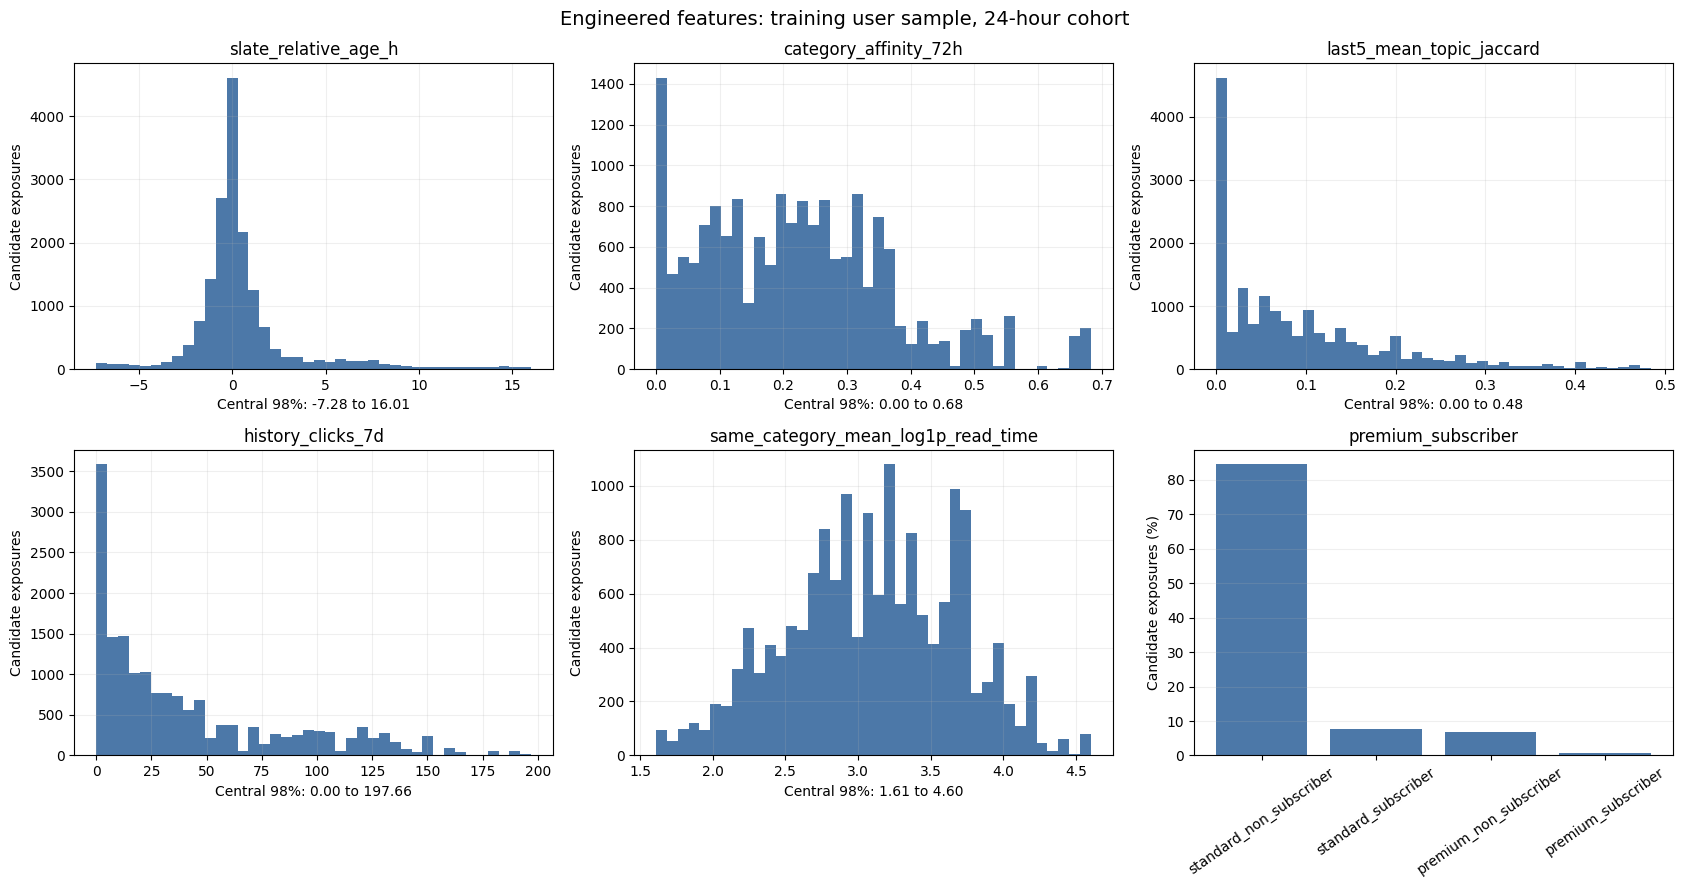

In [55]:
# Five numeric distributions and the four access groups.
# Numeric panels show the central 98%; the summary table above retains full tails.
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(axes.flat[:5], engineered_numeric):
    values = pd.to_numeric(eligible[feature], errors="coerce").dropna()
    lower, upper = values.quantile([0.01, 0.99])
    central = values.between(lower, upper)
    ax.hist(values.loc[central], bins=40, color="#4C78A8")
    ax.set_title(feature)
    ax.set_xlabel(f"Central 98%: {lower:.2f} to {upper:.2f}")
    ax.set_ylabel("Candidate exposures")
    ax.grid(alpha=0.2)

ax = axes.flat[5]
ax.bar(
    access_distribution["premium_subscriber"],
    access_distribution["share_pct"],
    color="#4C78A8",
)
ax.set_title("premium_subscriber")
ax.set_ylabel("Candidate exposures (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.2)
fig.suptitle("Engineered features: training user sample, 24-hour cohort", fontsize=14)
fig.tight_layout()
plt.show()


,feature,bucket,min_value,max_value,exposures,clicks,candidate_ctr
0,slate_relative_age_h,Q1,-18.263056,-1.690278,1727,87,0.050376
1,slate_relative_age_h,Q2,-1.686667,-0.887639,1727,81,0.046902
2,slate_relative_age_h,Q3,-0.886667,-0.471667,1727,93,0.053851
3,slate_relative_age_h,Q4,-0.470833,-0.173889,1727,145,0.083961
4,slate_relative_age_h,Q5,-0.173889,0.000000,2257,327,0.144883
5,slate_relative_age_h,Q6,0.000556,0.193611,1196,168,0.140468
6,slate_relative_age_h,Q7,0.193889,0.597222,1726,266,0.154114
7,slate_relative_age_h,Q8,0.597361,1.217778,1727,292,0.169079
8,slate_relative_age_h,Q9,1.218333,3.603889,1727,312,0.180660
9,slate_relative_age_h,Q10,3.605139,23.630556,1727,159,0.092067


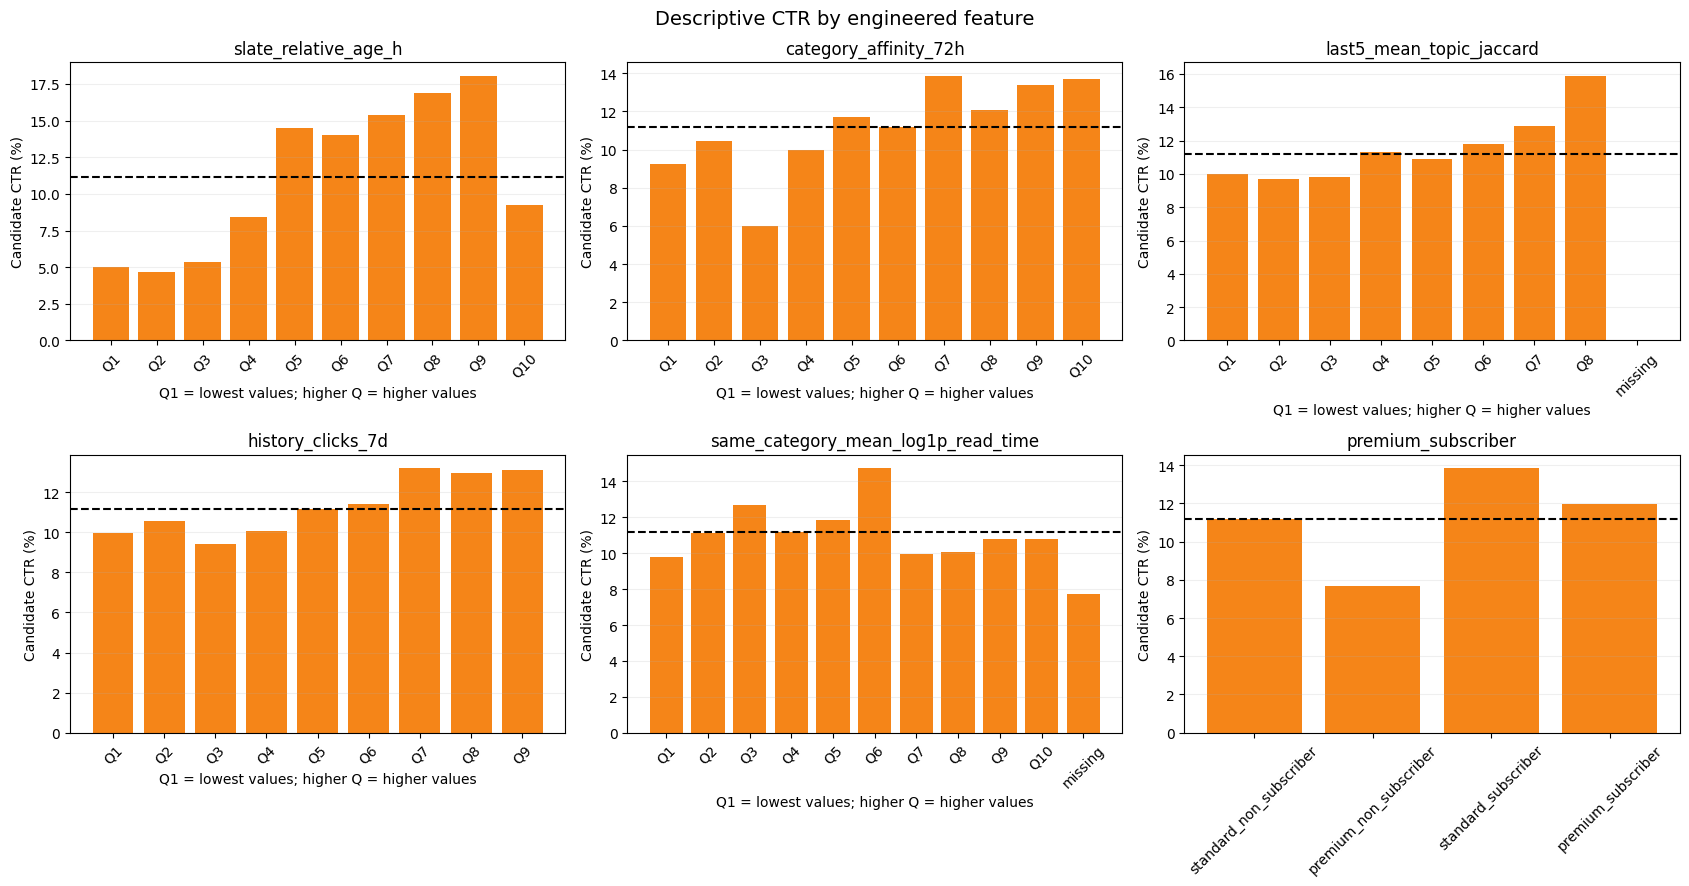

In [56]:
# Descriptive candidate-level click rates by quantile or access group.
# Shared user/context features cannot rank candidates within the same slate alone.
def _ctr_table(frame, feature):
    values = pd.Series(np.nan, index=frame.index, dtype=float)
    if feature == "premium_subscriber":
        bucket = frame[feature].fillna("missing").astype(str)
    else:
        values = pd.to_numeric(frame[feature], errors="coerce")
        valid = values.dropna()
        bucket = pd.Series("missing", index=frame.index, dtype=object)
        if valid.nunique() < 2:
            bucket.loc[valid.index] = "constant"
        else:
            codes = pd.qcut(valid, q=10, labels=False, duplicates="drop")
            bucket.loc[valid.index] = codes.map(
                lambda code: f"Q{int(code) + 1}"
            )
    table = (
        frame.assign(bucket=bucket, feature_value=values)
        .groupby("bucket", sort=False)
        .agg(
            exposures=("clicked", "size"),
            clicks=("clicked", "sum"),
            min_value=("feature_value", "min"),
            max_value=("feature_value", "max"),
        )
        .reset_index()
    )
    table["candidate_ctr"] = table["clicks"] / table["exposures"]
    table["feature"] = feature
    if feature != "premium_subscriber":
        table["q_number"] = pd.to_numeric(
            table["bucket"].str.extract(r"^Q([0-9]+)$")[0],
            errors="coerce",
        )
        table = table.sort_values("q_number", na_position="last")
    return table[[
        "feature", "bucket", "min_value", "max_value",
        "exposures", "clicks", "candidate_ctr",
    ]]


ctr_tables = pd.concat(
    [_ctr_table(eligible, feature) for feature in
     [*engineered_numeric, "premium_subscriber"]],
    ignore_index=True,
)
display(ctr_tables)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(
    axes.flat, [*engineered_numeric, "premium_subscriber"]
):
    subset = ctr_tables.loc[ctr_tables["feature"].eq(feature)].copy()
    if feature != "premium_subscriber":
        # Sort Q1, Q2, ... numerically; missing values come last.
        subset["q_number"] = pd.to_numeric(
            subset["bucket"].str.extract(r"^Q([0-9]+)$")[0],
            errors="coerce",
        )
        subset = subset.sort_values("q_number", na_position="last")
    positions = np.arange(len(subset))
    ax.bar(positions, 100 * subset["candidate_ctr"], color="#F58518")
    ax.set_xticks(positions, subset["bucket"])
    ax.axhline(100 * eligible["clicked"].mean(), linestyle="--", color="black")
    ax.set_title(feature)
    ax.set_ylabel("Candidate CTR (%)")
    if feature != "premium_subscriber":
        ax.set_xlabel("Q1 = lowest values; higher Q = higher values")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Descriptive CTR by engineered feature", fontsize=14)
fig.tight_layout()
plt.show()


### Engineered-feature EDA notes for the current train sample

- The plots and CTR table above describe only sampled train users and candidates published within 24 hours of an impression. Record the sample size and missing counts before drawing conclusions; the saved Step 3 features cover all shown candidates.
- `slate_relative_age_h` is signed. Inspect its CTR shape before trying a nonlinear model representation; ordinary `log1p` is unsuitable for negative values.
- `category_affinity_72h` and `last5_mean_topic_jaccard` compare a candidate with fixed history. Compare their quantile CTRs and the missing groups.
- `history_clicks_7d` is shared across a user's candidates in an impression. Compare its tail and CTR groups; Step 3 may also save a log variant if train skewness supports it.
- The exploratory `same_category_mean_log1p_read_time` here is computed on the sample. Step 3 saves `same_category_mean_read_time` and may add `same_category_mean_read_time_log1p`; use the Step 3 files for modeling.
- `premium_subscriber` groups may be uneven. Interpret their CTRs with exposure counts and use the one-hot columns in Step 3 for model input.